## Nome:Mayara Cristina
## Matricula:574
-----


# **ATV 12 — Organização de Dados**

Esta atividade pratica a **organização e a apresentação de dados** em Estatística: classificação de variáveis, distribuições de frequências (qualitativas, quantitativas discretas e contínuas agrupadas em classes), representações gráficas e tabelas de contingência.

**Objetivos**
- Classificar variáveis (tipo e escala de medida).
- Construir **tabelas de frequências** (fi, fr, fr%, Fac, xi) para cada tipo de variável.
- Agrupar dados contínuos em classes (regra de **Sturges**, amplitude, intervalo de classe).
- Construir **gráficos** adequados: barras, setores, bastões, histograma, polígono de frequências.


## Instruções gerais

- Execute as células na ordem em que aparecem.
- Sempre **identifique o tipo da variável** antes de escolher a tabela e o gráfico.
- Ferramentas úteis:
  - `Series.value_counts()` → frequências absolutas (`sort_index()` para ordenar pelos valores);
  - `Series.cumsum()` → frequências acumuladas;
  - `plt.bar`, `plt.pie`, `plt.stem`, `plt.step` → gráficos.


In [1]:
# Imports úteis para toda a atividade
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.precision", 4)



## Exercício 1 — **Classificação de variáveis** (tipo e escala)

**Contexto**: Um hospital registra, para cada paciente atendido, as variáveis abaixo.

| # | **Variável**                                         | **Exemplo de valor**        |
|:-:|------------------------------------------------------|-----------------------------|
| 1 | Sexo                                                 | F                           |
| 2 | Tipo sanguíneo                                       | AB                          |
| 3 | Grau de escolaridade (fundamental, médio, superior)  | Médio                       |
| 4 | Número de filhos                                     | 2                           |
| 5 | Altura (cm)                                          | 168,5                       |
| 6 | Temperatura corporal (°C)                            | 36,8                        |
| 7 | Satisfação (ruim, regular, boa, ótima)               | Boa                         |
| 8 | Número de internações nos últimos 5 anos             | 0                           |
| 9 | Estado civil                                         | Casado(a)                   |
| 10 | Tempo de espera no pronto-atendimento (min)         | 37                          |

1. Classifique cada variável como **qualitativa nominal**, **qualitativa ordinal**, **quantitativa discreta** ou **quantitativa contínua**.
2. Informe a **escala de medida** de cada uma (nominal, ordinal, intervalar ou razão).
3. Organize a classificação em um `DataFrame` (colunas *Tipo* e *Escala*).
4. Conte quantas variáveis há em cada tipo.


In [2]:
classificacao = pd.DataFrame({
    "Variável": [
        "Sexo",
        "Tipo sanguíneo",
        "Grau de escolaridade",
        "Número de filhos",
        "Altura (cm)",
        "Temperatura corporal (°C)",
        "Satisfação",
        "Número de internações nos últimos 5 anos",
        "Estado civil",
        "Tempo de espera no pronto-atendimento (min)"
    ],
    "Tipo": [
        "Qualitativa nominal",
        "Qualitativa nominal",
        "Qualitativa ordinal",
        "Quantitativa discreta",
        "Quantitativa contínua",
        "Quantitativa contínua",
        "Qualitativa ordinal",
        "Quantitativa discreta",
        "Qualitativa nominal",
        "Quantitativa contínua"
    ],
    "Escala": [
        "Nominal",
        "Nominal",
        "Ordinal",
        "Razão",
        "Razão",
        "Intervalar",
        "Ordinal",
        "Razão",
        "Nominal",
        "Razão"
    ]
}).set_index("Variável")

display(classificacao)

print("Quantidade de variáveis por tipo:")
display(classificacao["Tipo"].value_counts().rename("Quantidade"))

,Tipo,Escala
Variável,,
Sexo,Qualitativa nominal,Nominal
Tipo sanguíneo,Qualitativa nominal,Nominal
Grau de escolaridade,Qualitativa ordinal,Ordinal
Número de filhos,Quantitativa discreta,Razão
Altura (cm),Quantitativa contínua,Razão
Temperatura corporal (°C),Quantitativa contínua,Intervalar
Satisfação,Qualitativa ordinal,Ordinal
Número de internações nos últimos 5 anos,Quantitativa discreta,Razão
Estado civil,Qualitativa nominal,Nominal


Quantidade de variáveis por tipo:


,Quantidade
Tipo,
Qualitativa nominal,3
Quantitativa contínua,3
Qualitativa ordinal,2
Quantitativa discreta,2


**Conclusão:** Foram identificadas 3 variáveis qualitativas nominais, 2 qualitativas ordinais, 2 quantitativas discretas e 3 quantitativas contínuas. As variáveis nominais representam categorias sem ordem, enquanto as ordinais possuem uma ordem. As discretas representam contagens e as contínuas representam medidas. A temperatura em graus Celsius utiliza a escala intervalar, pois seu zero não representa ausência de temperatura. As demais variáveis quantitativas utilizam a escala de razão.



## Exercício 2 — Distribuição de frequências de uma variável **qualitativa**

**Contexto**: Em uma campanha de doação, foi registrado o **tipo sanguíneo** de **n = 40** doadores. Os dados brutos estão na célula abaixo.

1. Identifique o tipo e a escala da variável.
2. Construa a **tabela de frequências** com **fi**, **fr** e **fr (%)**, ordenada de forma decrescente por fi.
3. Verifique que Σfi = n e Σfr = 1.
4. Construa um **gráfico de barras** (fi) e um **gráfico de setores** (%).
5. Indique a **moda** e conclua.


In [3]:
# Dados brutos — tipo sanguíneo de 40 doadores
sangue = pd.Series([
    'O', 'A', 'O', 'O', 'A', 'A', 'O', 'B', 'O', 'B',
    'O', 'O', 'O', 'B', 'AB', 'O', 'A', 'O', 'O', 'A',
    'O', 'B', 'O', 'B', 'A', 'A', 'A', 'AB', 'AB', 'O',
    'A', 'O', 'A', 'A', 'A', 'O', 'A', 'B', 'A', 'O'
], name="Tipo sanguíneo")


Tipo: qualitativa nominal
Escala: nominal


,fi,fr,fr (%)
Tipo sanguíneo,,,
O,17,0.425,42.5
A,14,0.350,35.0
B,6,0.150,15.0
AB,3,0.075,7.5


Soma de fi: 40
Soma de fr: 0.9999999999999999


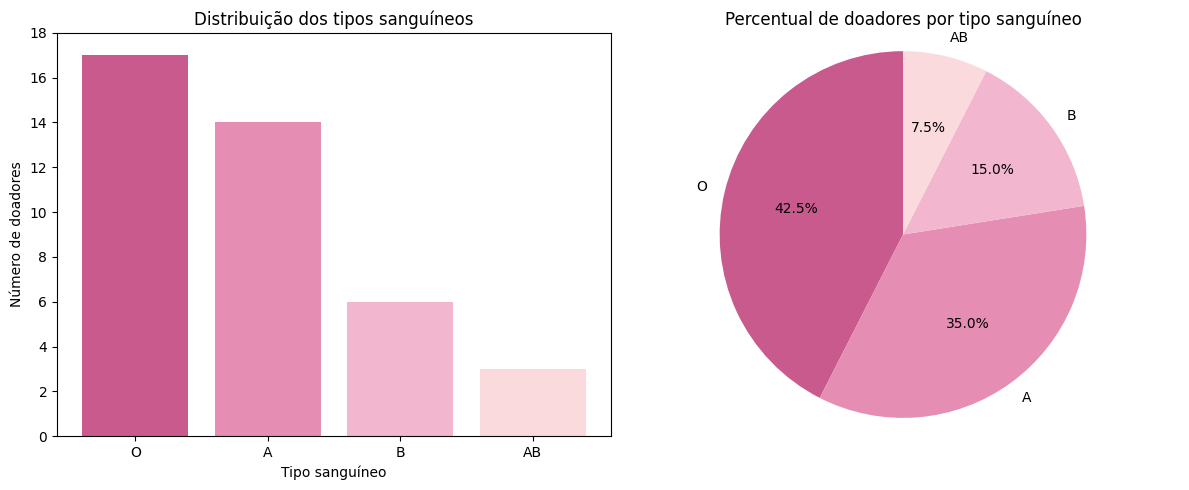

Moda: O


In [4]:
print("Tipo: qualitativa nominal")
print("Escala: nominal")

# Frequências em ordem decrescente
fi = sangue.value_counts()

tabela_sangue = pd.DataFrame({
    "fi": fi,
    "fr": fi / len(sangue),
    "fr (%)": fi / len(sangue) * 100
})

display(tabela_sangue)

# Verificação dos totais
print("Soma de fi:", tabela_sangue["fi"].sum())
print("Soma de fr:", tabela_sangue["fr"].sum())

assert tabela_sangue["fi"].sum() == len(sangue)
assert np.isclose(tabela_sangue["fr"].sum(), 1)

# Gráficos
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

cores = ["#C85A8E", "#E58DB2", "#F2B6CF", "#FADADD"]

eixos[0].bar(
    tabela_sangue.index,
    tabela_sangue["fi"],
    color=cores
)
eixos[0].set_title("Distribuição dos tipos sanguíneos")
eixos[0].set_xlabel("Tipo sanguíneo")
eixos[0].set_ylabel("Número de doadores")
eixos[0].set_yticks(range(0, 19, 2))

eixos[1].pie(
    tabela_sangue["fi"],
    labels=tabela_sangue.index,
    autopct="%1.1f%%",
    colors=cores,
    startangle=90
)
eixos[1].set_title("Percentual de doadores por tipo sanguíneo")
eixos[1].axis("equal")

plt.tight_layout()
plt.show()

print("Moda:", sangue.mode().iloc[0])

**Conclusão:**
O tipo sanguíneo é uma variável qualitativa nominal, pois suas categorias não possuem uma ordem. O tipo O é a moda, com 17 doadores, correspondendo a 42,5% do total. O tipo AB é o menos frequente, com 3 doadores, equivalentes a 7,5%. A soma das frequências absolutas é 40 e a soma das frequências relativas é 1, correspondendo a 100% dos doadores.


## Exercício 3 — Distribuição de frequências de uma variável **quantitativa discreta**

**Contexto**: Registrou-se o **número de consultas** realizadas em 12 meses por **n = 30** pacientes de uma unidade de saúde (dados brutos abaixo).

1. Construa a tabela com **fi**, **fr**, **fr (%)**, **Fac** (frequência acumulada) e **Fac (%)**.
2. Construa um **gráfico de bastões** (fi) e um **gráfico em degraus** da frequência acumulada.
3. Responda: (a) Qual é a **moda**? (b) Quantos pacientes (e que %) fizeram **no máximo 2** consultas? (c) Qual a % que fez **4 ou mais**?


In [5]:
# Dados brutos — nº de consultas em 12 meses (30 pacientes)
consultas = pd.Series([
    5, 0, 3, 3, 2, 2, 4, 2, 2, 6, 0, 4, 1, 4, 1,
    1, 2, 1, 0, 5, 4, 1, 3, 2, 3, 3, 1, 2, 2, 3
], name="Consultas")


Tipo: quantitativa discreta
Escala: razão


,fi,fr,fr (%),Fac,Fac (%)
Consultas,,,,,
0,3,0.1000,10.0000,3,10.0000
1,6,0.2000,20.0000,9,30.0000
2,8,0.2667,26.6667,17,56.6667
3,6,0.2000,20.0000,23,76.6667
4,4,0.1333,13.3333,27,90.0000
5,2,0.0667,6.6667,29,96.6667
6,1,0.0333,3.3333,30,100.0000


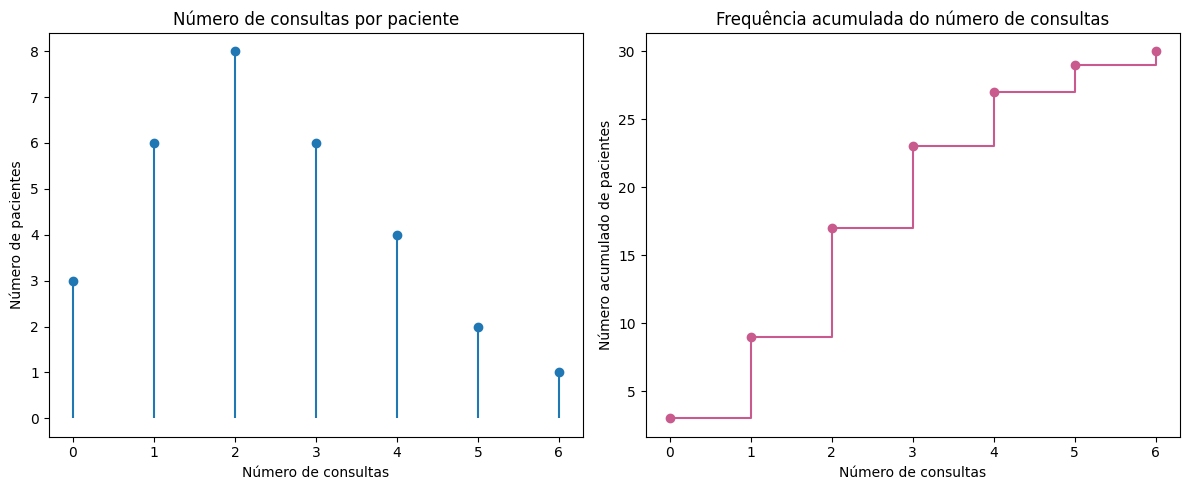

a) Moda: 2 consultas.
b) No máximo 2 consultas: 17 pacientes (56.67%).
c) 4 ou mais consultas: 23.33%.


In [6]:
print("Tipo: quantitativa discreta")
print("Escala: razão")

# Frequências ordenadas pelo número de consultas
fi = consultas.value_counts().sort_index()

tabela_consultas = pd.DataFrame({
    "fi": fi,
    "fr": fi / len(consultas),
    "fr (%)": fi / len(consultas) * 100,
    "Fac": fi.cumsum(),
    "Fac (%)": fi.cumsum() / len(consultas) * 100
})

display(tabela_consultas)

# Gráficos
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

eixos[0].stem(
    tabela_consultas.index,
    tabela_consultas["fi"],
    basefmt=" "
)
eixos[0].set_title("Número de consultas por paciente")
eixos[0].set_xlabel("Número de consultas")
eixos[0].set_ylabel("Número de pacientes")
eixos[0].set_xticks(tabela_consultas.index)

eixos[1].step(
    tabela_consultas.index,
    tabela_consultas["Fac"],
    where="post",
    color="#C85A8E"
)
eixos[1].plot(
    tabela_consultas.index,
    tabela_consultas["Fac"],
    "o",
    color="#C85A8E"
)
eixos[1].set_title("Frequência acumulada do número de consultas")
eixos[1].set_xlabel("Número de consultas")
eixos[1].set_ylabel("Número acumulado de pacientes")
eixos[1].set_xticks(tabela_consultas.index)

plt.tight_layout()
plt.show()

# Respostas
moda = consultas.mode().iloc[0]

ate_duas = (consultas <= 2).sum()
percentual_ate_duas = ate_duas / len(consultas) * 100

quatro_ou_mais = (consultas >= 4).sum()
percentual_quatro_ou_mais = quatro_ou_mais / len(consultas) * 100

print(f"a) Moda: {moda} consultas.")
print(
    f"b) No máximo 2 consultas: {ate_duas} pacientes "
    f"({percentual_ate_duas:.2f}%)."
)
print(f"c) 4 ou mais consultas: {percentual_quatro_ou_mais:.2f}%.")

**Conclusão:**
O número de consultas é uma variável quantitativa discreta, de escala de razão, pois representa uma contagem e possui zero absoluto. A moda é 2 consultas, realizadas por 8 pacientes. No total, 17 pacientes fizeram no máximo 2 consultas, correspondendo a aproximadamente 56,67% da amostra. Já 7 pacientes fizeram 4 ou mais consultas, representando aproximadamente 23,33% do total.